In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

C:\Users\mralo\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
df = pd.read_excel("large_orders_data.xlsx")


In [3]:
df.isnull().sum()

Day                0
Promotion          0
Previous Orders    0
Orders             0
dtype: int64

In [4]:
from scipy import stats

z_scores = np.abs(stats.zscore(df['Orders']))
threshold = 3 
df = df[z_scores < threshold]


In [5]:
df.rename(columns={
    'Day': 'Day_of_Week',
    'Promotion': 'Promotion_Active',
    'Previous Orders': 'Previous_Day_Orders',
    'Orders': 'Current_Day_Orders'
}, inplace=True)

In [6]:
df.head()

,Day_of_Week,Promotion_Active,Previous_Day_Orders,Current_Day_Orders
0,1,0,142,123
1,2,1,175,189
2,3,0,182,177
3,4,0,192,212
4,5,0,131,146


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Day_of_Week          200 non-null    int64
 1   Promotion_Active     200 non-null    int64
 2   Previous_Day_Orders  200 non-null    int64
 3   Current_Day_Orders   200 non-null    int64
dtypes: int64(4)
memory usage: 6.4 KB


C:\Users\mralo\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\mralo\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\mralo\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\mralo\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating

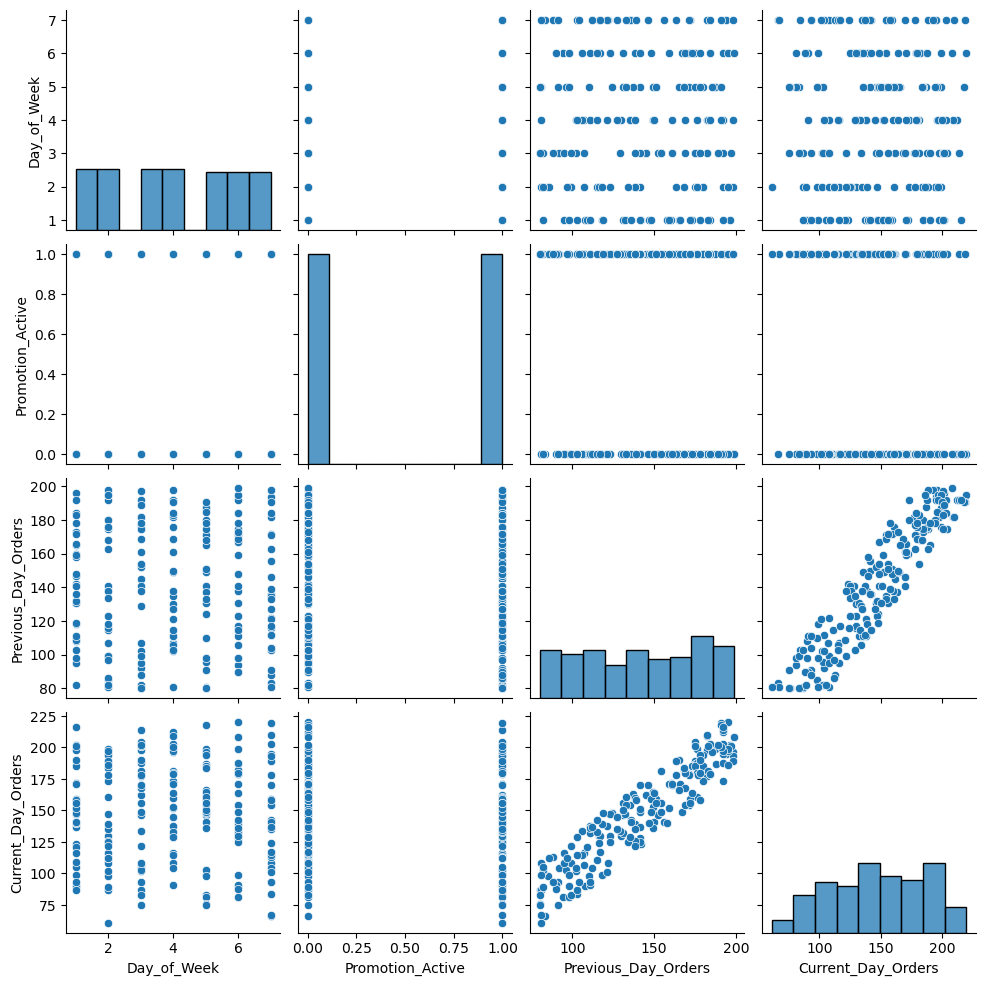

In [8]:
sns.pairplot(df)
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error


In [10]:
df

,Day_of_Week,Promotion_Active,Previous_Day_Orders,Current_Day_Orders
0,1,0,142,123
1,2,1,175,189
2,3,0,182,177
3,4,0,192,212
4,5,0,131,146
...,...,...,...,...
195,7,1,104,93
196,1,1,172,156
197,2,1,97,112
198,3,0,189,202


In [11]:
X = df[['Day_of_Week', 'Promotion_Active', 'Previous_Day_Orders']]  
y = df['Current_Day_Orders']

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [13]:
model = LinearRegression()

In [14]:
model.fit(X_train, y_train)

LinearRegression()

In [15]:
y_pred = model.predict(X_test)

In [16]:
mse = mean_squared_error(y_test, y_pred)
print(f"Mean Squared Error: {mse}")


Mean Squared Error: 170.61196315719766


In [17]:
comparison = pd.DataFrame({'Actual Orders': y_test, 'Predicted Orders': y_pred})
print(comparison.head())

     Actual Orders  Predicted Orders
95              83         85.860209
15             111        121.763828
30             107        113.673693
158            218        197.328673
128            122        143.971282


In [18]:
columns = ['Day_of_Week', 'Promotion_Active', 'Previous_Day_Orders']


day_of_week = int(input("Enter Day of the Week (numeric value, e.g., 1 for Monday): "))
promotion_active = int(input("Is the Promotion Active? (1 for Yes, 0 for No): "))
previous_day_orders = int(input("Enter Previous Day Orders: "))

new_day = pd.DataFrame([[day_of_week, promotion_active, previous_day_orders]], columns=columns)

print("\nThe DataFrame you created is:")
print(new_day)
predicted_orders = model.predict(new_day)
print(f"Predicted Orders for new day: {predicted_orders[0]}")

Enter Day of the Week (numeric value, e.g., 1 for Monday): 1
Is the Promotion Active? (1 for Yes, 0 for No): 2
Enter Previous Day Orders: 532

The DataFrame you created is:
   Day_of_Week  Promotion_Active  Previous_Day_Orders
0            1                 2                  532
Predicted Orders for new day: 536.8774519002849
